In [2]:
# Lädt externe Python-Module vor jedem Zellenausführen automatisch neu
%load_ext autoreload
%autoreload 2

# Macht Matplotlib-Plots interaktiv (Drehen, Zoomen in 3D)
%matplotlib widget

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Play, jslink, HBox, IntSlider, interactive_output
from IPython.display import display

# eigenen Module importieren
import nbody.Anfangsbedingungen as ab
import nbody.Dynamik as dyn
import nbody.Integrator as int
import nbody.Analyse as an

# G in SI-Einheiten imporiteren
from scipy.constants import G as G_real


**Experiment - Periodische und reguläre Lösung**\
Euler-Lösung (kollinear und zirkulär)\
Lagrange (reeles Beispiel: Sonne-Jupiter-Trojaner)

**Euler-Lösung:**\
qualitative und quantitative Visualisierung der Orbits

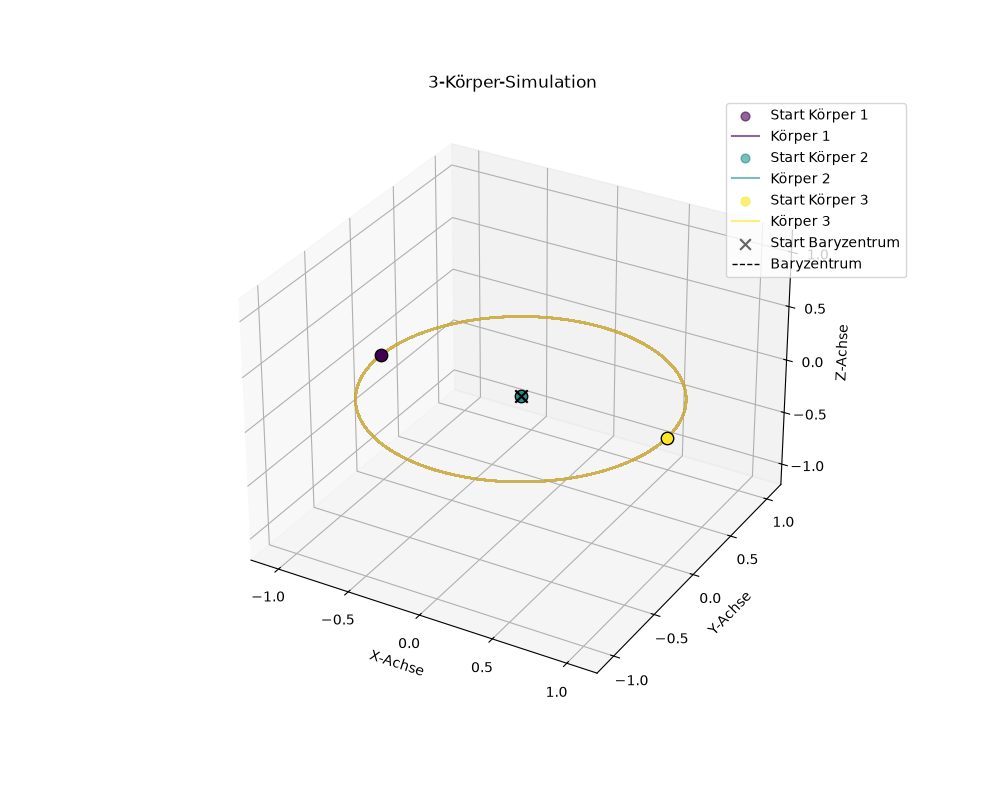

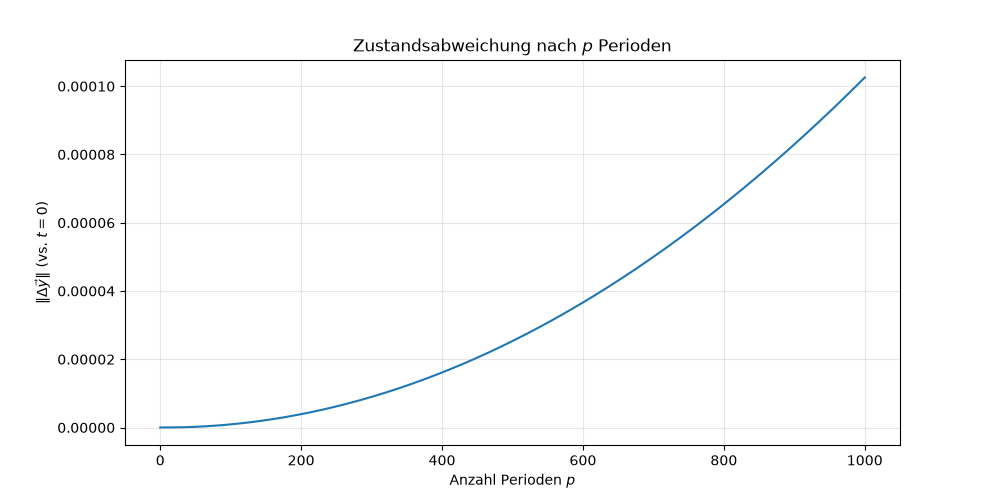

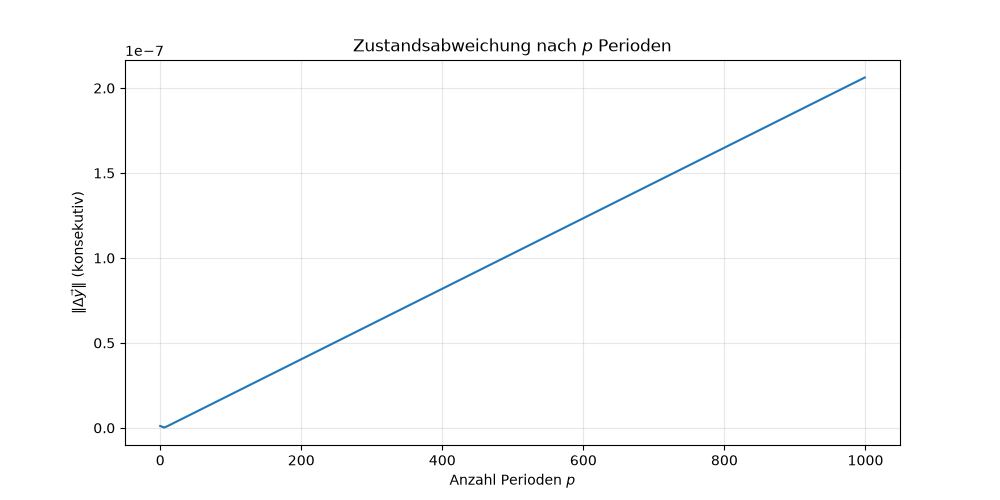

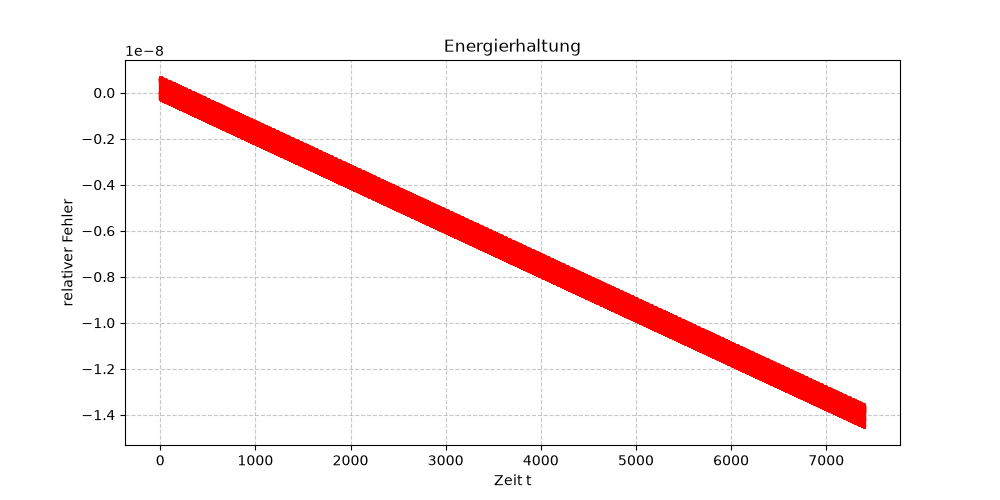

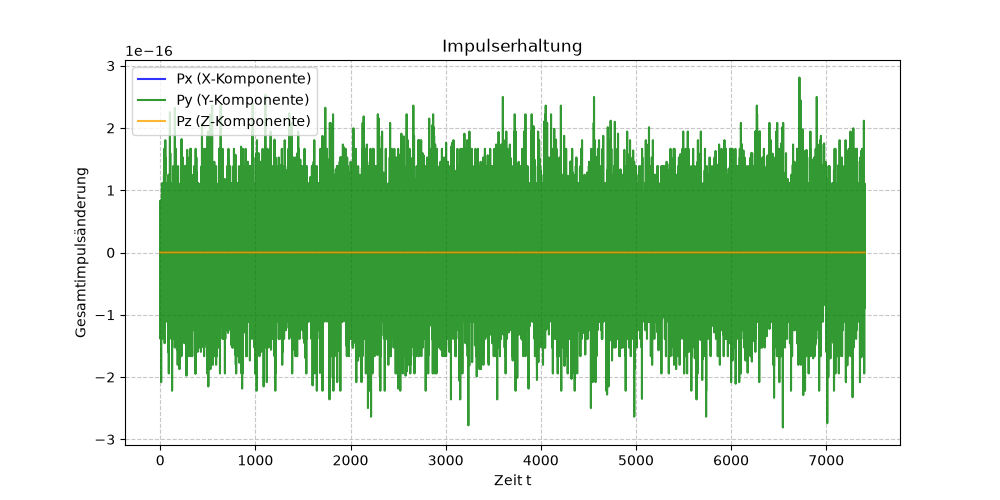

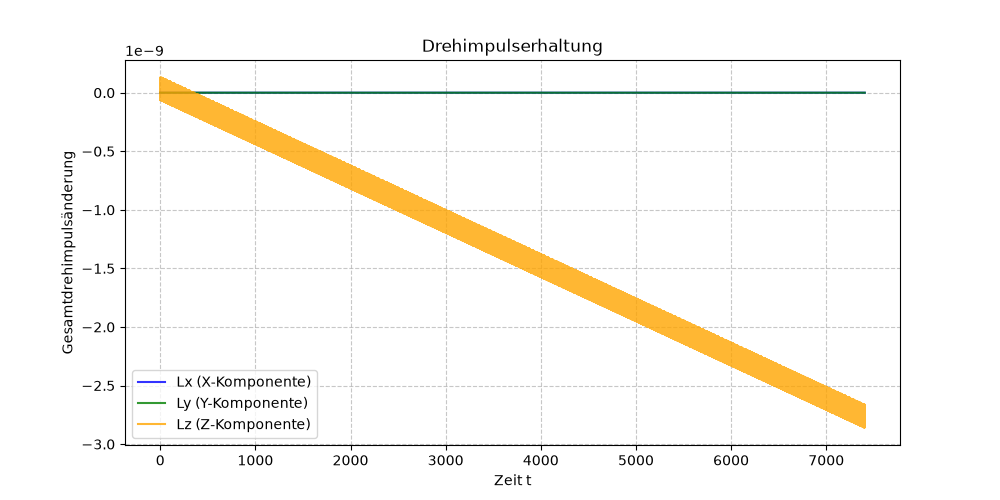

In [5]:
# Die Periodendauer bestimmen (für die Analyse)
m_ref=1.0
a=1
G=1.0

T_E = an.period_euler(m_ref, a, G)
p = 1000 # Anzahl Perioden
n_pts_per_T = 200 # Anzahl Punkte pro Periode
frames = p * n_pts_per_T + 1 # +1 da t_eval = t_end/(frames-1), so mgl. direkt auf T_1 T_2 etc. zu landen

# Die referenz Anfangsbedingungen bestimmem
y0_ref, m_ref, G, r_ref, v_ref = ab.initial_conditions_euler(a=1.0, G=1.0, m_ref=m_ref)
sol_ref = int.run_n_body_simulation(y0_ref, m_ref, G, t_start=0, t_end=T_E*p, frames=frames)

fig = an.create_plot(sol_ref.y, m_ref)

# Zustand normalisieren
# y0_ref, m_ref, G, r_ref, v_ref von oben übernehmen;
# Einheiten aus den Referenzen generieren
units = an.compute_nbody_units(m_ref, r_ref, G)
# Zustand normieren
sol_ref_n = an.normalize_trajectory(sol_ref,  units, N=3, m=m_ref)

fig, ax = an.plot_periodicity(sol_ref_n, n_pts_per_T, "vs_initial")
fig, ax = an.plot_periodicity(sol_ref_n, n_pts_per_T, "consecutive")

fig_E, ax_E = an.plot_conservation_of_energy(sol_ref_n.y, sol_ref_n.m, G, sol_ref_n.t)
fig_P, ax_P = an.plot_conservation_of_momentum(sol_ref_n.y, sol_ref_n.m, sol_ref_n.t)
fig_P, ax_P = an.plot_conservation_of_angular_momentum(sol_ref_n.y, sol_ref_n.m, sol_ref_n.t)

**Lagrange-Lösung:**\
qualitative und quantitative Visualisierung der Orbits

/Users/silashungerbuhler/Desktop/Simulation 3BP/src/nbody/Analyse.py:403: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10, 5))


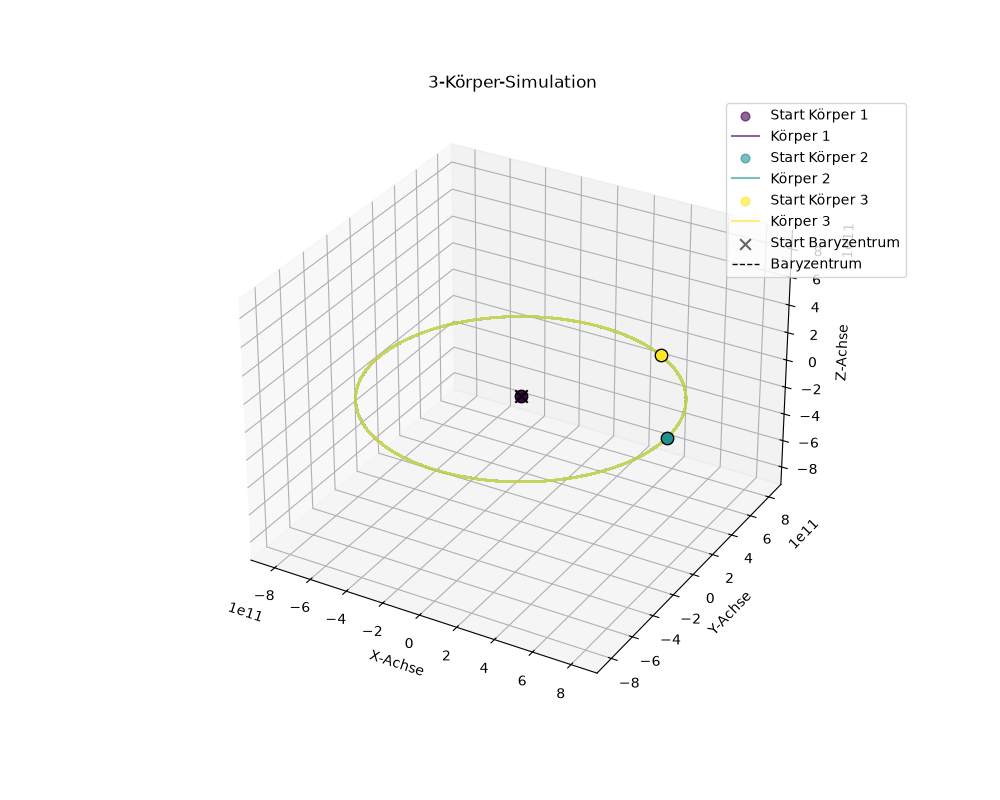

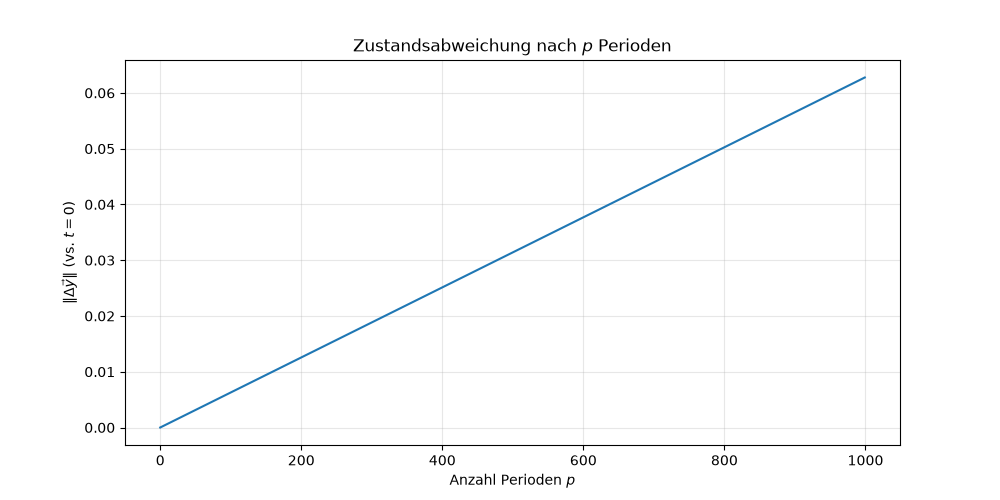

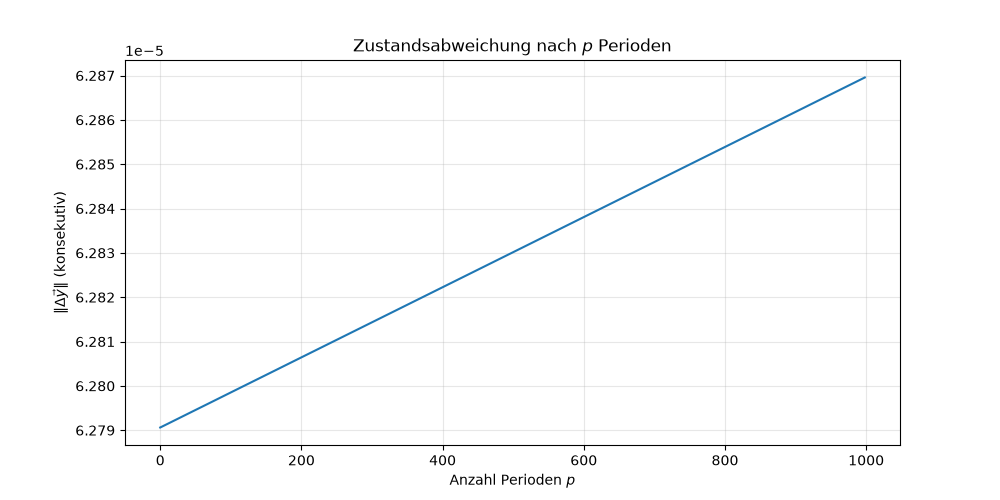

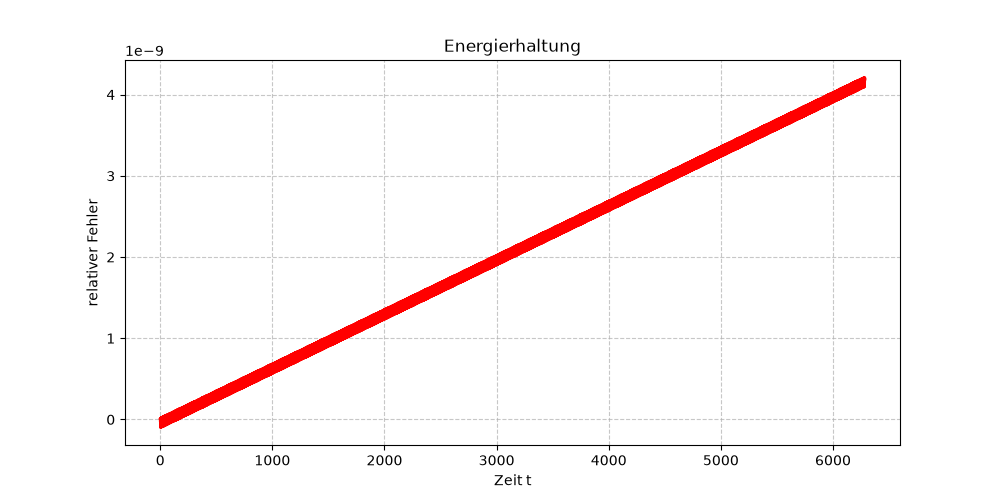

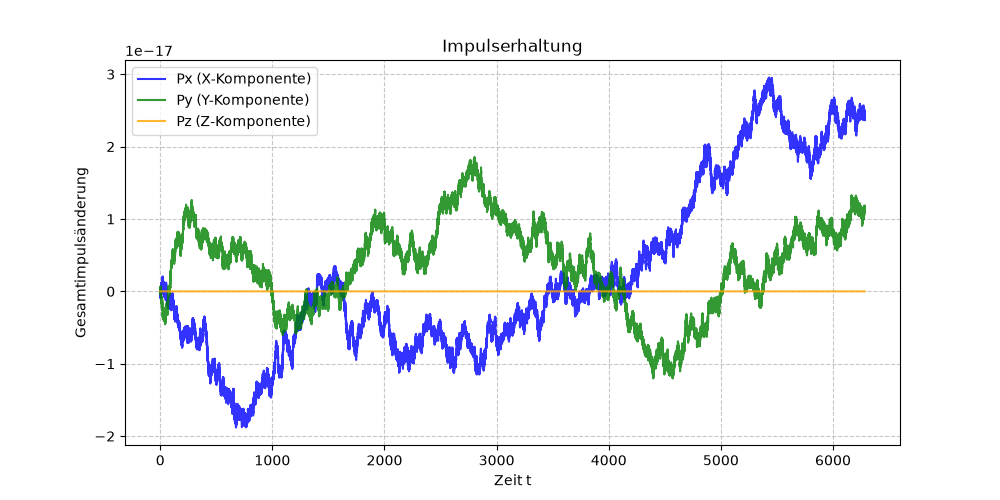

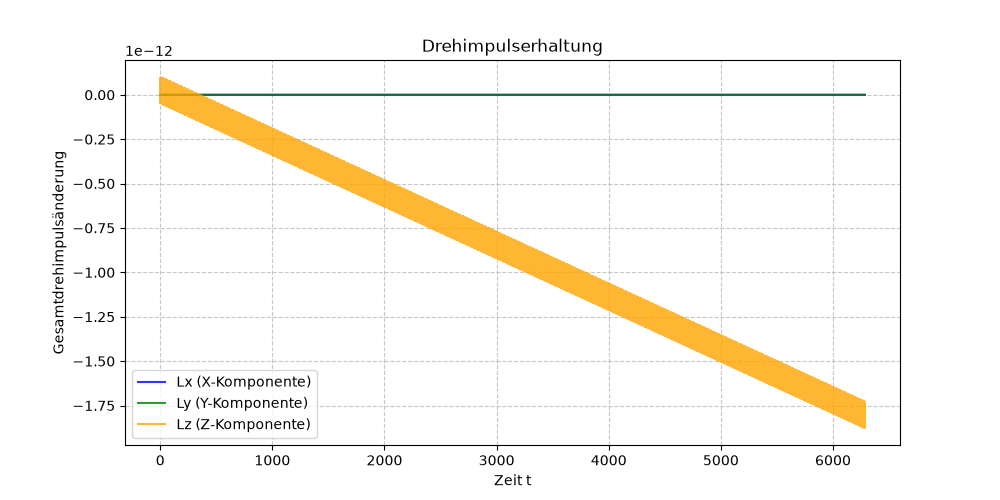

In [ ]:
# Lagrange Lösung (SI-Einheiten)

# Anfangebedingungen
a = 7.785e11 # a=1# Durchschnittlche Distanz zwischen Jupiter und Sonne in Meter
m_ref = 1.98e30, 1.899e27, 0 # m_ref=(1, 1, 1) # Die Massen des Systems, Sonne, Jupiter, Trojaner (vernachlässigbar klein)

# Periode bestimmen
T_L = an.period_lagrange(m_ref, a, G_real)
p = 1000 # Anzahl simulierten Perioden
n_pts_per_p = 200 # Anzahl Punkte pro Periode
frames =p * n_pts_per_p

# Die referenz Anfangsbedingungen bestimmen
y0_ref, m_ref, G, r_ref, v_ref = ab.initial_conditions_lagrange(m_ref=m_ref, a=a, G=G_real)

sol_ref = int.run_n_body_simulation(y0_ref, m_ref, G, t_start=0, t_end=T_L*p, frames=frames)

fig = an.create_plot(sol_ref.y, m_ref)

# Zustand normalisieren
# y0_ref, m_ref, G, r_ref, v_ref von oben übernehmen;
# Einheiten aus den Referenzen generieren
units = an.compute_nbody_units(m_ref, r_ref, G)
# Zustand normieren
sol_ref_n = an.normalize_trajectory(sol_ref,  units, N=3, m=m_ref)

fig, ax = an.plot_periodicity(sol_ref_n, n_pts_per_T, "vs_initial")
fig, ax = an.plot_periodicity(sol_ref_n, n_pts_per_T, "consecutive")

fig_E, ax_E = an.plot_conservation_of_energy(sol_ref_n.y, sol_ref_n.m, G, sol_ref_n.t)
fig_P, ax_P = an.plot_conservation_of_momentum(sol_ref_n.y, sol_ref_n.m, sol_ref_n.t)
fig_P, ax_P = an.plot_conservation_of_angular_momentum(sol_ref_n.y, sol_ref_n.m, sol_ref_n.t)


In [ ]:
# plt.close("all")